In [1]:
# Analyzing the trends of covid-19 with python

In [7]:
# Proble Statements ->https://drive.google.com/file/d/1JraPenCa5CZ_6UucYCsHDbxDqc00sAf7/view

In [18]:
import pandas as pd

In [5]:
df=pd.read_csv("C:/Users/lenovo/Downloads/Covid_19_Clean_Complete (2).csv")

In [6]:
df

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.939110,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.153300,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.033900,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.506300,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.202700,17.873900,2020-01-22,0,0,0,0,Africa
...,...,...,...,...,...,...,...,...,...,...
49063,NaN,Sao Tome and Principe,0.186400,6.613100,2020-07-27,865,14,734,117,Africa
49064,NaN,Yemen,15.552727,48.516388,2020-07-27,1691,483,833,375,Eastern Mediterranean
49065,NaN,Comoros,-11.645500,43.333300,2020-07-27,354,7,328,19,Africa
49066,NaN,Tajikistan,38.861000,71.276100,2020-07-27,7235,60,6028,1147,Europe


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  14664 non-null  object 
 1   Country/Region  49068 non-null  object 
 2   Lat             49068 non-null  float64
 3   Long            49068 non-null  float64
 4   Date            49068 non-null  object 
 5   Confirmed       49068 non-null  int64  
 6   Deaths          49068 non-null  int64  
 7   Recovered       49068 non-null  int64  
 8   Active          49068 non-null  int64  
 9   WHO Region      49068 non-null  object 
dtypes: float64(2), int64(4), object(4)
memory usage: 3.7+ MB


In [11]:
df.shape

(49068, 10)

In [13]:
rename_col={ 
    "Province/State":"state",
    "Country/Region":"country"
}
df.rename(columns=rename_col,inplace=True)

In [14]:
df.head()

,state,country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


In [16]:
confirmed_cases=df.groupby(["Date"])["Confirmed"].sum().reset_index()

In [17]:
confirmed_cases

,Date,Confirmed
0,2020-01-22,555
1,2020-01-23,654
2,2020-01-24,941
3,2020-01-25,1434
4,2020-01-26,2118
...,...,...
183,2020-07-23,15510481
184,2020-07-24,15791645
185,2020-07-25,16047190
186,2020-07-26,16251796


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

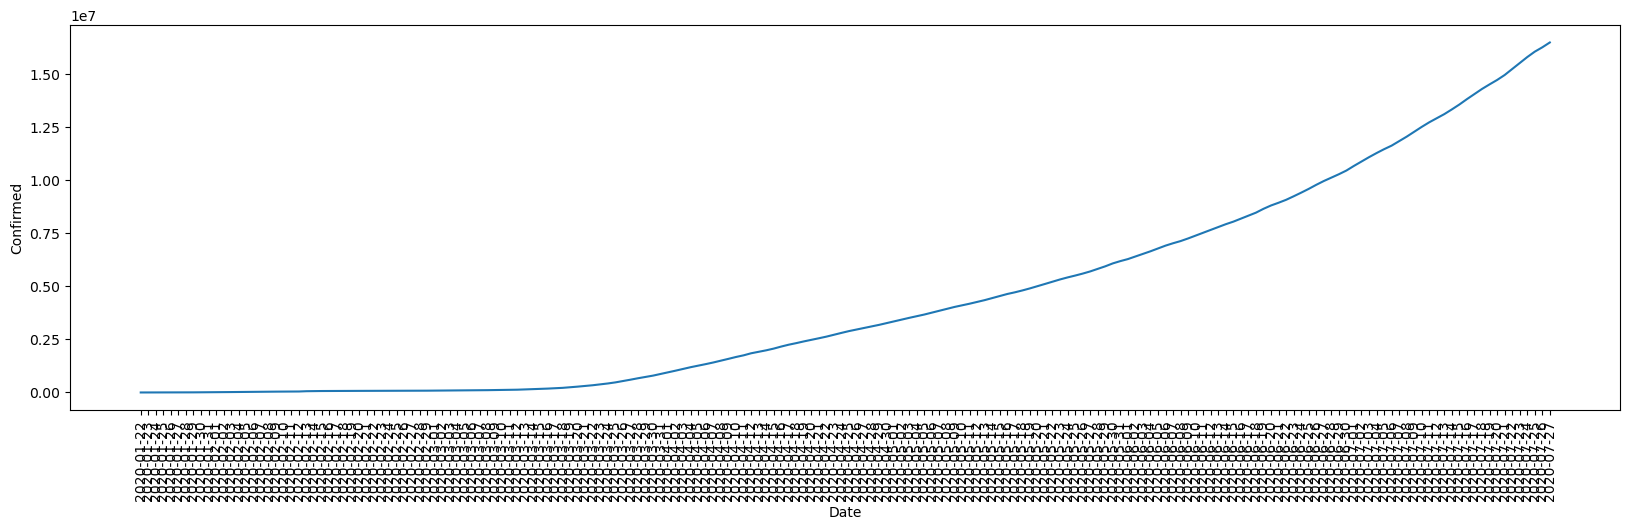

In [23]:
plt.figure(figsize=(20,5))
sns.lineplot(data=confirmed_cases,x="Date",y="Confirmed")
plt.xticks(rotation=90)
plt.show()

In [26]:
death_cases=df.groupby(["Date"])["Deaths"].sum().reset_index()
death_cases

,Date,Deaths
0,2020-01-22,17
1,2020-01-23,18
2,2020-01-24,26
3,2020-01-25,42
4,2020-01-26,56
...,...,...
183,2020-07-23,633506
184,2020-07-24,639650
185,2020-07-25,644517
186,2020-07-26,648621


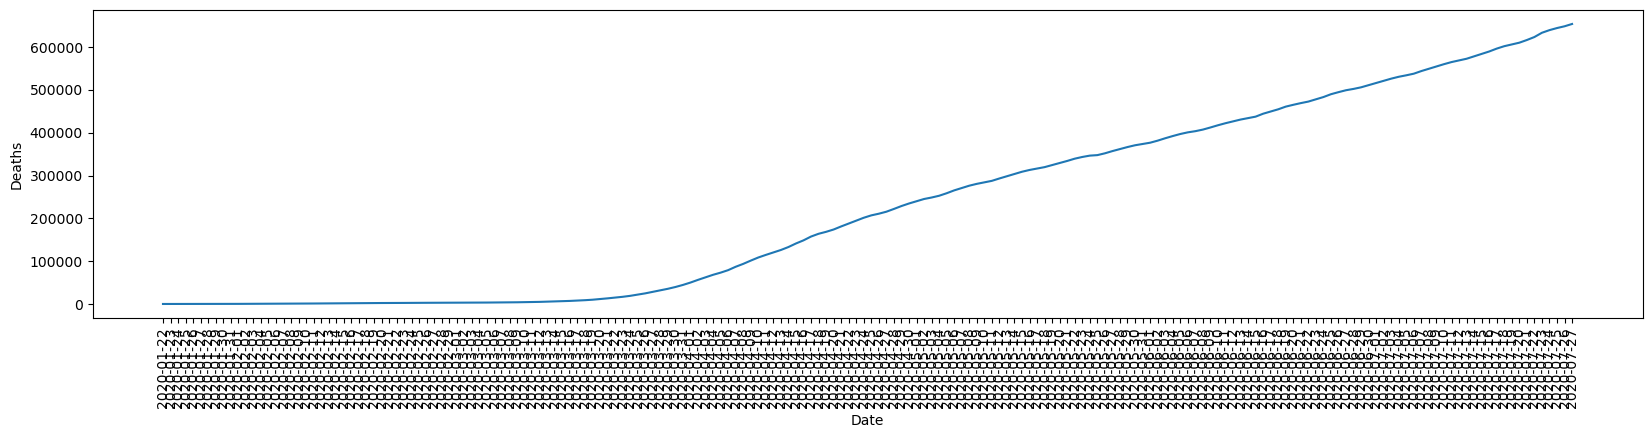

In [29]:
plt.figure(figsize=(20,4))
sns.lineplot(data=death_cases,x="Date",y="Deaths")
plt.xticks(rotation=90)
plt.show()

In [30]:
# Let's find the most affected countries

In [34]:
data_countries=df.groupby("country")[["Confirmed","Active","Recovered","Deaths"]].sum().reset_index()

In [36]:
# Top 3 countries->

top3_confirmed = data_countries.sort_values(by="Confirmed",ascending=False).head(3)
top3_confirmed

,country,Confirmed,Active,Recovered,Deaths
173,US,224345948,156981121,56353416,11011411
23,Brazil,89524967,31094060,54492873,3938034
138,Russia,45408411,19668578,25120448,619385


In [37]:
top3_deaths=data_countries.sort_values(by="Deaths", ascending=False).head(3)
top3_deaths

,country,Confirmed,Active,Recovered,Deaths
173,US,224345948,156981121,56353416,11011411
177,United Kingdom,26748587,22624595,126217,3997775
23,Brazil,89524967,31094060,54492873,3938034


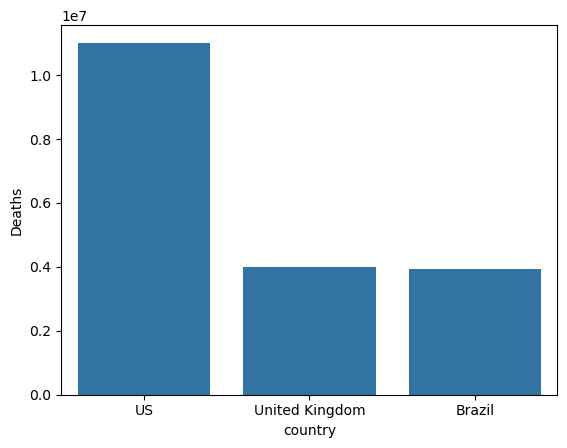

In [41]:
sns.barplot(data=top3_deaths,x="country",y="Deaths")
plt.show()

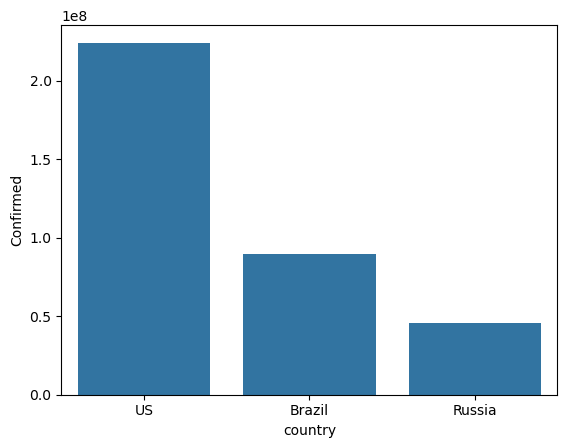

In [44]:
sns.barplot(data=top3_confirmed,x="country",y="Confirmed")
plt.show()

In [47]:
data_us = df[df["country"]=="US"]
data_usimport 

,state,country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
223,NaN,US,40.0,-100.0,2020-01-22,1,0,0,1,Americas
484,NaN,US,40.0,-100.0,2020-01-23,1,0,0,1,Americas
745,NaN,US,40.0,-100.0,2020-01-24,2,0,0,2,Americas
1006,NaN,US,40.0,-100.0,2020-01-25,2,0,0,2,Americas
1267,NaN,US,40.0,-100.0,2020-01-26,5,0,0,5,Americas
...,...,...,...,...,...,...,...,...,...,...
47986,NaN,US,40.0,-100.0,2020-07-23,4038816,144430,1233269,2661117,Americas
48247,NaN,US,40.0,-100.0,2020-07-24,4112531,145560,1261624,2705347,Americas
48508,NaN,US,40.0,-100.0,2020-07-25,4178970,146465,1279414,2753091,Americas
48769,NaN,US,40.0,-100.0,2020-07-26,4233923,146935,1297863,2789125,Americas


In [49]:
data_us = us.groupby("Date")[["Confirmed","Deaths","Active","Recovered"]].sum().reset_index()
data_us

,Date,Confirmed,Deaths,Active,Recovered
0,2020-01-22,1,0,1,0
1,2020-01-23,1,0,1,0
2,2020-01-24,2,0,2,0
3,2020-01-25,2,0,2,0
4,2020-01-26,5,0,5,0
...,...,...,...,...,...
183,2020-07-23,4038816,144430,2661117,1233269
184,2020-07-24,4112531,145560,2705347,1261624
185,2020-07-25,4178970,146465,2753091,1279414
186,2020-07-26,4233923,146935,2789125,1297863


In [50]:
brazil=df[df["country"]=="Brazil"]

In [51]:
brazil

,state,country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
28,NaN,Brazil,-14.235,-51.9253,2020-01-22,0,0,0,0,Americas
289,NaN,Brazil,-14.235,-51.9253,2020-01-23,0,0,0,0,Americas
550,NaN,Brazil,-14.235,-51.9253,2020-01-24,0,0,0,0,Americas
811,NaN,Brazil,-14.235,-51.9253,2020-01-25,0,0,0,0,Americas
1072,NaN,Brazil,-14.235,-51.9253,2020-01-26,0,0,0,0,Americas
...,...,...,...,...,...,...,...,...,...,...
47791,NaN,Brazil,-14.235,-51.9253,2020-07-23,2287475,84082,1620313,583080,Americas
48052,NaN,Brazil,-14.235,-51.9253,2020-07-24,2343366,85238,1693214,564914,Americas
48313,NaN,Brazil,-14.235,-51.9253,2020-07-25,2394513,86449,1785359,522705,Americas
48574,NaN,Brazil,-14.235,-51.9253,2020-07-26,2419091,87004,1812913,519174,Americas


In [54]:
data_brazil=brazil.groupby("Date")[["Confirmed","Deaths","Active","Recovered"]].sum().reset_index()
data_brazil

,Date,Confirmed,Deaths,Active,Recovered
0,2020-01-22,0,0,0,0
1,2020-01-23,0,0,0,0
2,2020-01-24,0,0,0,0
3,2020-01-25,0,0,0,0
4,2020-01-26,0,0,0,0
...,...,...,...,...,...
183,2020-07-23,2287475,84082,583080,1620313
184,2020-07-24,2343366,85238,564914,1693214
185,2020-07-25,2394513,86449,522705,1785359
186,2020-07-26,2419091,87004,519174,1812913


In [63]:
russ=df[df["country"]=="Russia"]

In [64]:
data_russ=russ.groupby("Date")[["Confirmed","Deaths","Active","Recovered"]].sum().reset_index()
data_russ

,Date,Confirmed,Deaths,Active,Recovered
0,2020-01-22,0,0,0,0
1,2020-01-23,0,0,0,0
2,2020-01-24,0,0,0,0
3,2020-01-25,0,0,0,0
4,2020-01-26,0,0,0,0
...,...,...,...,...,...
183,2020-07-23,793720,12873,201552,579295
184,2020-07-24,799499,13026,198745,587728
185,2020-07-25,805332,13172,196096,596064
186,2020-07-26,811073,13249,198652,599172


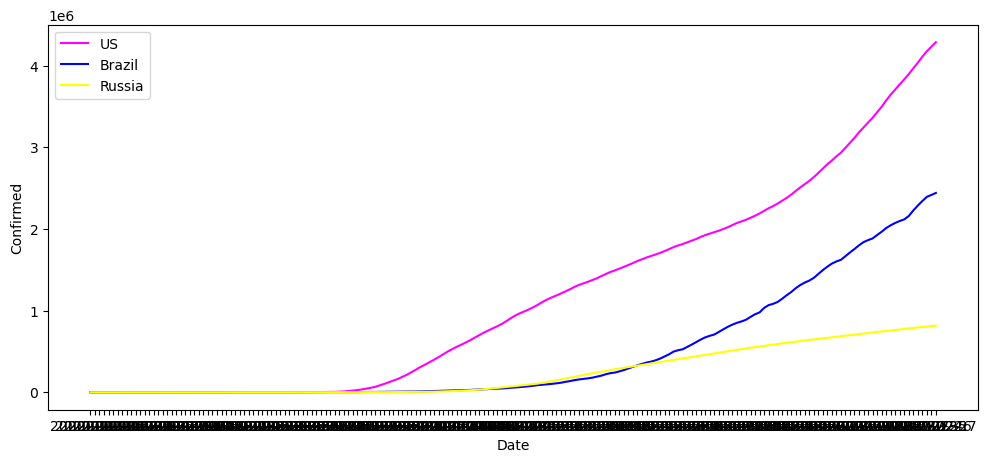

In [65]:
plt.figure(figsize=(12,5))
sns.lineplot(data=data_us, x="Date", y="Confirmed", color="magenta", label="US")
sns.lineplot(data=data_brazil, x="Date", y="Confirmed", color="blue", label="Brazil")
sns.lineplot(data=data_russ, x="Date", y="Confirmed", color="yellow", label="Russia")
plt.show()

In [66]:
# Homework ->
# Find top3 Death cases and compare using line plot
# Find top3 Active cases and compare using line plot
# Find top3 Recovered cases and compare using line plot

In [67]:
# Prophet -> It is a timeseries forecasting model/tool develop by facebook that's designed to be easy to use and effective 

In [68]:
# it is particularly usefull for data that has strong seasonal effects (daily/weekly pattern)

In [69]:
!pip install prophet

   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------- ----------------------------- 3.1/12.1 MB 16.6 MB/s eta 0:00:01
   ------------------------ --------------- 7.3/12.1 MB 19.4 MB/s eta 0:00:01
   -------------------------------------- - 11.8/12.1 MB 20.1 MB/s eta 0:00:01
   ---------------------------------------  12.1/12.1 MB 20.1 MB/s eta 0:00:01
   ---------------------------------------- 12.1/12.1 MB 13.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 14.1 MB/s eta 0:00:00

   -------- ------------------------------- 1/5 [importlib_resources]
   ---------------- ----------------------- 2/5 [holidays]
   ---------------- ----------------------- 2/5 [holidays]
   ---------------- ----------------------- 2/5 [holidays]
   ---------------- ----------------------- 2/5 [holidays]
   ---------------- ----------------------- 2/5 [holidays]
   ---------------- -----

In [70]:
from prophet import Prophet

In [71]:
# Forcasting for the confirmed cases

In [72]:
confirmed_cases

,Date,Confirmed
0,2020-01-22,555
1,2020-01-23,654
2,2020-01-24,941
3,2020-01-25,1434
4,2020-01-26,2118
...,...,...
183,2020-07-23,15510481
184,2020-07-24,15791645
185,2020-07-25,16047190
186,2020-07-26,16251796


### two thing need for prophet  ds (date) and y(thing you want to forecast)

In [74]:
# we need to rename the columns as ds(datesstamp) and y(values)

prophet_data=confirmed_cases.rename(columns={"Date":"ds","Confirmed":"y"})
prophet_data

,ds,y
0,2020-01-22,555
1,2020-01-23,654
2,2020-01-24,941
3,2020-01-25,1434
4,2020-01-26,2118
...,...,...
183,2020-07-23,15510481
184,2020-07-24,15791645
185,2020-07-25,16047190
186,2020-07-26,16251796


In [75]:
model=Prophet()

In [76]:
model.fit(prophet_data)

22:17:37 - cmdstanpy - INFO - Chain [1] start processing
22:17:38 - cmdstanpy - INFO - Chain [1] done processing


In [78]:
future = model.make_future_dataframe(periods=7)       # For future 7 days
future

,ds
0,2020-01-22
1,2020-01-23
2,2020-01-24
3,2020-01-25
4,2020-01-26
...,...
190,2020-07-30
191,2020-07-31
192,2020-08-01
193,2020-08-02


In [79]:
forecast = model.predict(future)

In [80]:
forecast

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2020-01-22,-9.356181e+03,-1.209611e+05,7.742307e+04,-9.356181e+03,-9.356181e+03,-10986.215104,-10986.215104,-10986.215104,-10986.215104,-10986.215104,-10986.215104,0.0,0.0,0.0,-2.034240e+04
1,2020-01-23,-6.667726e+03,-1.079187e+05,9.438870e+04,-6.667726e+03,-6.667726e+03,-1078.892495,-1078.892495,-1078.892495,-1078.892495,-1078.892495,-1078.892495,0.0,0.0,0.0,-7.746619e+03
2,2020-01-24,-3.979272e+03,-9.774436e+04,1.143294e+05,-3.979272e+03,-3.979272e+03,10103.254163,10103.254163,10103.254163,10103.254163,10103.254163,10103.254163,0.0,0.0,0.0,6.123982e+03
3,2020-01-25,-1.290817e+03,-9.464653e+04,1.132639e+05,-1.290817e+03,-1.290817e+03,13670.219215,13670.219215,13670.219215,13670.219215,13670.219215,13670.219215,0.0,0.0,0.0,1.237940e+04
4,2020-01-26,1.397637e+03,-9.383766e+04,1.092557e+05,1.397637e+03,1.397637e+03,7218.147794,7218.147794,7218.147794,7218.147794,7218.147794,7218.147794,0.0,0.0,0.0,8.615785e+03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,2020-07-30,1.674928e+07,1.664028e+07,1.684998e+07,1.674245e+07,1.675398e+07,-1078.892495,-1078.892495,-1078.892495,-1078.892495,-1078.892495,-1078.892495,0.0,0.0,0.0,1.674820e+07
191,2020-07-31,1.695352e+07,1.685525e+07,1.707431e+07,1.694112e+07,1.696281e+07,10103.254163,10103.254163,10103.254163,10103.254163,10103.254163,10103.254163,0.0,0.0,0.0,1.696362e+07
192,2020-08-01,1.715776e+07,1.705697e+07,1.728521e+07,1.713594e+07,1.717557e+07,13670.219215,13670.219215,13670.219215,13670.219215,13670.219215,13670.219215,0.0,0.0,0.0,1.717143e+07
193,2020-08-02,1.736200e+07,1.725544e+07,1.748106e+07,1.732950e+07,1.738815e+07,7218.147794,7218.147794,7218.147794,7218.147794,7218.147794,7218.147794,0.0,0.0,0.0,1.736922e+07


In [82]:
forecast[["yhat_lower","yhat_upper","yhat"]]

,yhat_lower,yhat_upper,yhat
0,-1.209611e+05,7.742307e+04,-2.034240e+04
1,-1.079187e+05,9.438870e+04,-7.746619e+03
2,-9.774436e+04,1.143294e+05,6.123982e+03
3,-9.464653e+04,1.132639e+05,1.237940e+04
4,-9.383766e+04,1.092557e+05,8.615785e+03
...,...,...,...
190,1.664028e+07,1.684998e+07,1.674820e+07
191,1.685525e+07,1.707431e+07,1.696362e+07
192,1.705697e+07,1.728521e+07,1.717143e+07
193,1.725544e+07,1.748106e+07,1.736922e+07


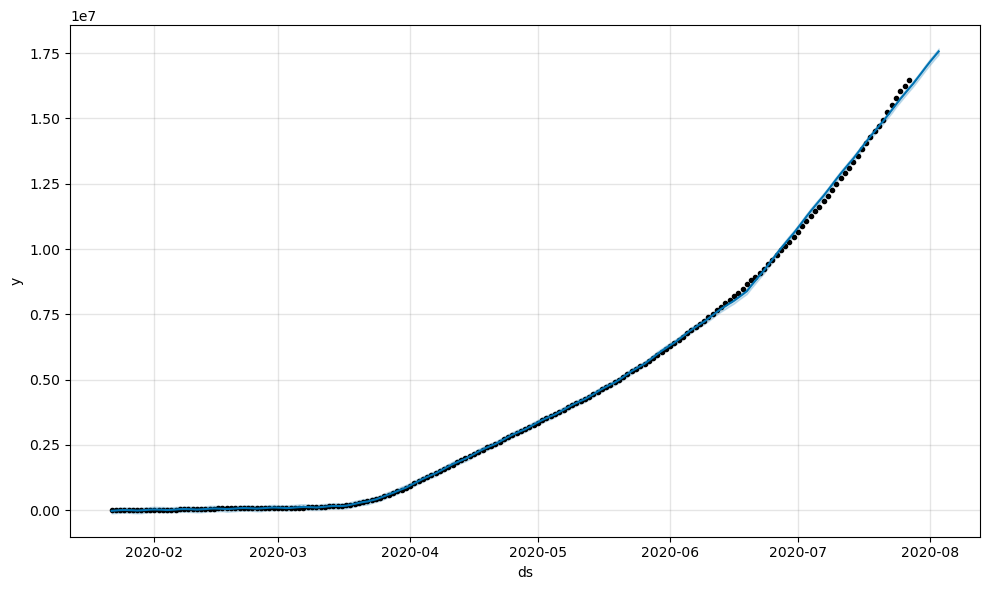

In [83]:
model.plot(forecast)
plt.show()

In [85]:
# use prophet for Active , Deaths , Recovered